## Preenfasis

### Configuración

In [1]:
from pathlib import Path

# Ruta base donde están TUS audios por género.
# Ejemplo con tu estructura: MusicaAndina/Seg_20s/Huaylash/...
# CAMBIA esta ruta a la que corresponda en tu máquina:
base_dir = Path(r'C:\Users\RICHI\Documents\Tesis\Data\GTZAN\Data\genres_original')

# Extensiones a procesar
EXTS = {'.wav', '.mp3', '.flac', '.ogg', '.m4a', '.aac'}

# Carpeta de salida (se crea en paralelo, preservando subcarpetas)
output_root = base_dir.parent / (base_dir.name + '_preenfasis')

# Parámetros de procesamiento
alpha = 0.97          # 0.95 -- 0.97 típico; a mayor alpha, más agudos
target_rms = None     # p.ej. 0.1 para fijar RMS; usa None para omitir
write_outputs = True  # True = guarda archivos en disco

base_dir, output_root

(WindowsPath('C:/Users/RICHI/Documents/Tesis/Data/GTZAN/Data/genres_original'),
 WindowsPath('C:/Users/RICHI/Documents/Tesis/Data/GTZAN/Data/genres_original_preenfasis'))

In [2]:
# ====================== Utilidades ======================
import numpy as np
import librosa
import soundfile as sf

def peak_normalize(x: np.ndarray, eps: float = 1e-9) -> np.ndarray:
    """Escala la señal a rango [-1, 1] por pico absoluto."""
    peak = np.max(np.abs(x)) + eps
    return (x / peak).astype(np.float32)

def rms(x: np.ndarray, eps: float = 1e-12) -> float:
    return float(np.sqrt(np.mean(np.square(x)) + eps))

def rms_normalize(x: np.ndarray, target: float) -> np.ndarray:
    """Ajusta el RMS de 'x' a 'target'."""
    current = rms(x)
    if current == 0:
        return x.astype(np.float32)
    return (x * (target / current)).astype(np.float32)

def normalize_wave(x: np.ndarray, target_rms: float | None) -> np.ndarray:
    """
    Normalización combinada: 
      1) Peak a [-1, 1] (garantiza rango)
      2) (Opcional) RMS objetivo
      3) Clip de seguridad a [-1, 1]
    """
    y = peak_normalize(x)
    if target_rms is not None:
        y = rms_normalize(y, target_rms)
        y = np.clip(y, -1.0, 1.0)
    return y.astype(np.float32)

def pre_emphasis(x: np.ndarray, alpha: float = 0.97) -> np.ndarray:
    """Filtro de 1er orden: y[n] = x[n] - alpha * x[n-1]."""
    if x.ndim > 1:
        x = np.mean(x, axis=0)       # a mono si entra multicanal
    y = np.empty_like(x, dtype=np.float32)
    y[0] = x[0]
    y[1:] = x[1:] - alpha * x[:-1]
    return y

def load_audio(path: Path, sr: int | None = None) -> tuple[np.ndarray, int]:
    """Carga audio (mono) con su frecuencia de muestreo original si sr=None."""
    x, sr = librosa.load(str(path), sr=sr, mono=True)
    return x.astype(np.float32), sr

def save_audio(path: Path, x: np.ndarray, sr: int):
    path.parent.mkdir(parents=True, exist_ok=True)
    sf.write(str(path), x.astype(np.float32), sr)  # WAV float32


In [3]:
# ====================== Procesamiento en lote ======================
from tqdm.auto import tqdm

def process_dataset(input_root: Path, output_root: Path, alpha: float = 0.97, 
                    target_rms: float | None = None, write: bool = True):
    input_root = Path(input_root)
    output_root = Path(output_root)

    files = [p for p in input_root.rglob('*') if p.suffix.lower() in EXTS]
    if not files:
        print('No se encontraron archivos de audio en:', input_root)
        return

    for src in tqdm(files, desc='Procesando audios'):
        rel = src.relative_to(input_root)
        dst = output_root / rel.with_suffix('.wav')  # salida en WAV

        try:
            # 1) Carga
            x, sr = load_audio(src)
            # 2) Normalización (RMS opcional) a [-1,1]
            x_norm = normalize_wave(x, target_rms=target_rms)
            # 3) Pre-énfasis
            x_pre = pre_emphasis(x_norm, alpha=alpha)
            # 4) Re-normaliza pico para evitar clipping tras el filtro
            x_out = peak_normalize(x_pre)

            if write:
                save_audio(dst, x_out, sr)
        except Exception as e:
            print(f'Error en {src}: {e}')

# Ejecuta el pipeline completo
process_dataset(base_dir, output_root, alpha=alpha, target_rms=target_rms, write=write_outputs)
print('Salida en:', output_root)


c:\Users\RICHI\anaconda3\envs\TesisRichiFix2\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
Procesando audios: 100%|██████████| 999/999 [00:23<00:00, 41.93it/s]

Salida en: C:\Users\RICHI\Documents\Tesis\Data\GTZAN\Data\genres_original_preenfasis


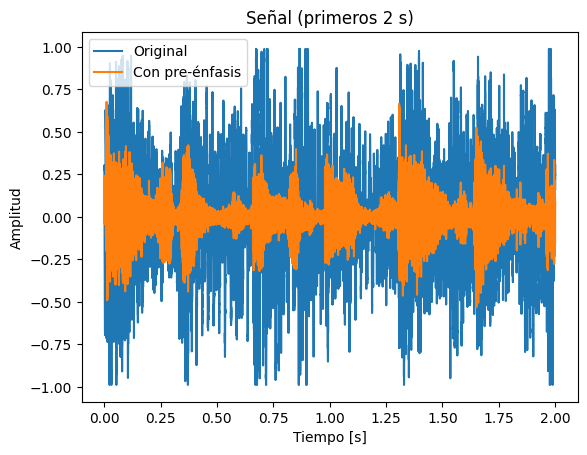

Archivo de muestra: hiphop.00073.wav
Escuchar original:


Escuchar con pre-énfasis:


In [4]:
# ====================== Vista previa (opcional) ======================
import random
import matplotlib.pyplot as plt
from IPython.display import Audio, display

candidates = [p for p in base_dir.rglob('*') if p.suffix.lower() in EXTS]
if candidates:
    sample_path = random.choice(candidates)
    x, sr = load_audio(sample_path)
    x_n = normalize_wave(x, target_rms=target_rms)
    x_p = pre_emphasis(x_n, alpha=alpha)
    x_p = peak_normalize(x_p)  # para escuchar sin clipping

    # gráfico de los primeros 2 s
    n = min(len(x), sr * 2)
    t = np.arange(n) / sr
    plt.figure()
    plt.plot(t, x[:n], label='Original')
    plt.plot(t, x_p[:n], label='Con pre-énfasis')
    plt.title('Señal (primeros 2 s)')
    plt.xlabel('Tiempo [s]')
    plt.ylabel('Amplitud')
    plt.legend()
    plt.show()

    print('Archivo de muestra:', sample_path.name)
    print('Escuchar original:')
    display(Audio(x, rate=sr))
    print('Escuchar con pre-énfasis:')
    display(Audio(x_p, rate=sr))
else:
    print('No hay archivos para vista previa.')

## Split de datos

In [8]:
from pathlib import Path
import random, shutil, csv
from typing import Dict, Tuple, List

# ==== CONFIG ====
IN_ROOT  = Path(r"C:\Users\RICHI\Documents\Tesis\Data\GTZAN\Data\GTZAN5Seg")  
OUT_ROOT = Path(r"C:\Users\RICHI\Documents\Tesis\Data\GTZAN\Data\GTZAN5seg_Split")          
RATIOS   = {"train": 0.70, "val": 0.20, "test": 0.10}
SEED     = 42
AUDIO_EXTS = {".wav", ".flac", ".mp3"}  # ajusta si usas otro formato
OVERWRITE = False  # True para reescribir si ya existe

random.seed(SEED)

def list_tracks_by_genre(in_root: Path) -> Dict[str, List[Path]]:
    """
    Devuelve un dict: genero -> lista de carpetas 'PistaFolder'
    Cada 'PistaFolder' contiene los segmentos .wav de esa pista.
    """
    mapping = {}
    for genre_dir in sorted(p for p in in_root.iterdir() if p.is_dir()):
        genre = genre_dir.name
        tracks = [p for p in genre_dir.iterdir() if p.is_dir()]
        # filtra carpetas vacías
        tracks = [t for t in tracks if any(f.suffix.lower() in AUDIO_EXTS for f in t.iterdir())]
        if tracks:
            mapping[genre] = tracks
    return mapping

def split_indices(n: int, ratios: Dict[str, float]) -> Dict[str, List[int]]:
    idxs = list(range(n))
    random.shuffle(idxs)
    n_train = int(round(ratios["train"] * n))
    n_val   = int(round(ratios["val"]   * n))
    # El resto a test (asegura suma)
    n_test  = max(0, n - n_train - n_val)
    return {
        "train": idxs[:n_train],
        "val":   idxs[n_train:n_train+n_val],
        "test":  idxs[n_train+n_val:]
    }

def copy_track_folder(track_dir: Path, dst_root: Path, genre: str, split: str, overwrite=False):
    """
    Copia todos los audios de track_dir a:
      dst_root/split/genre/track_dir.name/*.wav
    """
    dst = dst_root / split / genre / track_dir.name
    dst.mkdir(parents=True, exist_ok=True)
    for f in track_dir.iterdir():
        if not f.is_file() or f.suffix.lower() not in AUDIO_EXTS:
            continue
        dfile = dst / f.name
        if dfile.exists() and not overwrite:
            continue
        shutil.copy2(f, dfile)

def write_manifest(rows: List[Tuple[str,str,str,str]], out_csv: Path):
    out_csv.parent.mkdir(parents=True, exist_ok=True)
    with out_csv.open("w", newline="", encoding="utf-8") as fh:
        w = csv.writer(fh)
        w.writerow(["split","genre","track_folder","rel_path"])
        w.writerows(rows)

def make_track_split(in_root: Path, out_root: Path, ratios: Dict[str,float], overwrite=False):
    genres_tracks = list_tracks_by_genre(in_root)
    if not genres_tracks:
        raise RuntimeError(f"No se encontraron carpetas de pistas en {in_root}")

    manifest_rows = []
    for genre, tracks in genres_tracks.items():
        if len(tracks) < 3:
            print(f"[AVISO] Género '{genre}' tiene pocas pistas ({len(tracks)}). El split puede quedar desequilibrado.")
        groups = split_indices(len(tracks), ratios)
        for split, idxs in groups.items():
            for i in idxs:
                track_dir = tracks[i]
                copy_track_folder(track_dir, out_root, genre, split, overwrite=overwrite)
                # registra cada archivo copiado en el manifiesto
                dst_base = out_root / split / genre / track_dir.name
                for f in sorted(track_dir.iterdir()):
                    if f.is_file() and f.suffix.lower() in AUDIO_EXTS:
                        rel = (dst_base / f.name).relative_to(out_root).as_posix()
                        manifest_rows.append((split, genre, track_dir.name, rel))

    write_manifest(manifest_rows, out_root / "manifest_tracks_split.csv")
    print("Split por pista completado.")
    print("Salida:", out_root)
    print("Manifiesto:", out_root / "manifest_tracks_split.csv")

# === Ejecutar ===
if __name__ == "__main__":
    OUT_ROOT.mkdir(parents=True, exist_ok=True)
    make_track_split(IN_ROOT, OUT_ROOT, RATIOS, overwrite=OVERWRITE)



Split por pista completado.
Salida: C:\Users\RICHI\Documents\Tesis\Data\GTZAN\Data\GTZAN5seg_Split
Manifiesto: C:\Users\RICHI\Documents\Tesis\Data\GTZAN\Data\GTZAN5seg_Split\manifest_tracks_split.csv


## Data Augmentation

### Configuración

### Utilidades y transformaciones

### Esquema de augmentations

### Procesamiento (solo train/) y guardado

In [9]:
# augment_tracks_by_technique.py
from pathlib import Path
import random, numpy as np
import librosa, soundfile as sf
from tqdm.auto import tqdm

# ==== CONFIG ====
TRAIN_ROOT = Path(r"C:\Users\RICHI\Documents\Tesis\Data\GTZAN\Data\GTZAN5seg_Split\train")  # AJUSTA
AUDIO_EXTS = {".wav"}
SEED = 42

# 2 variantes por técnica
AUG_PER_TECH = 2

# Rangos
TIME_STRETCH_RANGE = (0.85, 1.15)        # ±15%
PITCH_SEMITONES_CHOICES = [-4, -3, -2, 2, 3, 4]
SNR_DB_RANGE = (15.0, 25.0)              # dB

TARGET_RMS = 0.1                         # normalización final

# =================

random.seed(SEED)
np.random.seed(SEED)

def list_track_folders(train_root: Path):
    pairs = []
    for gdir in sorted(p for p in train_root.iterdir() if p.is_dir()):
        for tdir in sorted(p for p in gdir.iterdir() if p.is_dir()):
            if any(f.is_file() and f.suffix.lower() in AUDIO_EXTS for f in tdir.iterdir()):
                pairs.append((gdir, tdir))
    return pairs

def rms(x): return float(np.sqrt(np.mean(x*x) + 1e-12))

def match_length(x: np.ndarray, target_len: int):
    if len(x) == target_len: return x
    if len(x) > target_len:  return x[:target_len]
    pad = target_len - len(x)
    L = pad // 2; R = pad - L
    return np.pad(x, (L, R), mode="reflect")

def normalize_to_rms(x: np.ndarray, target_rms: float):
    cur = rms(x)
    if cur < 1e-8: return x
    y = x * (target_rms / cur)
    peak = np.max(np.abs(y))
    if peak > 1.0: y = y / peak
    return y.astype(np.float32)

def load_mono(path: Path):
    y, sr = librosa.load(str(path), sr=None, mono=True)
    return y.astype(np.float32), sr

def save_wav(path: Path, y: np.ndarray, sr: int):
    path.parent.mkdir(parents=True, exist_ok=True)
    sf.write(str(path), y, sr)

# --- Técnicas individuales ---
def apply_time_stretch(y, sr):
    rate = random.uniform(*TIME_STRETCH_RANGE)
    y2 = librosa.effects.time_stretch(y, rate=rate)
    y2 = match_length(y2, len(y))
    return normalize_to_rms(y2, TARGET_RMS), {"time_stretch": rate}

def apply_pitch_shift(y, sr):
    semit = random.choice(PITCH_SEMITONES_CHOICES)
    y2 = librosa.effects.pitch_shift(y, sr=sr, n_steps=semit)
    return normalize_to_rms(y2, TARGET_RMS), {"pitch_semitones": semit}

def apply_noise(y, sr):
    snr_db = random.uniform(*SNR_DB_RANGE)
    p_signal = np.mean(y**2) + 1e-12
    snr_lin = 10.0**(snr_db/10.0)
    p_noise = p_signal / snr_lin
    noise = np.random.normal(0.0, np.sqrt(p_noise), size=y.shape).astype(np.float32)
    y2 = y + noise
    return normalize_to_rms(y2, TARGET_RMS), {"snr_db": snr_db}

TECHS = {
    "TS": apply_time_stretch,
    "PS": apply_pitch_shift,
    "NS": apply_noise,
}

def process_track_with_tech(genre_dir: Path, track_dir: Path, tech_code: str, variant_idx: int):
    """Crea <track>__<TECH><nn>/ con todos los segmentos transformados por la MISMA técnica."""
    dst_track = genre_dir / f"{track_dir.name}__{tech_code}{variant_idx:02d}"
    dst_track.mkdir(parents=True, exist_ok=True)

    # Elegimos parámetros una sola vez si la técnica los necesita?
    # Para coherencia, aplicamos la MISMA transformación por archivo PERO con parámetros
    # independientes puede introducir micro-variación. Si quieres idénticos parámetros,
    # descomenta/ajusta aquí para fijarlos y pasarlos a la función.
    params_used = None

    for src in sorted(f for f in track_dir.iterdir() if f.is_file() and f.suffix.lower() in AUDIO_EXTS):
        try:
            y, sr = load_mono(src)
            y_aug, params = TECHS[tech_code](y, sr)
            if params_used is None: params_used = params
            save_wav(dst_track / src.name, y_aug, sr)
        except Exception as e:
            print(f"[WARN] fallo en {src}: {e}")

    # guarda params de referencia
    (dst_track / "_aug_params.txt").write_text(
        "\n".join([f"{k}={v}" for k, v in (params_used or {}).items()]),
        encoding="utf-8"
    )

def augment_train_per_tech(train_root: Path, aug_per_tech: int):
    pairs = list_track_folders(train_root)
    if not pairs:
        print("No hay pistas en train/.")
        return
    print(f"Pistas: {len(pairs)} | Técnicas: {list(TECHS.keys())} | Variantes/tech: {aug_per_tech}")
    for genre_dir, track_dir in tqdm(pairs, desc="Tracks"):
        for tech_code in TECHS.keys():
            for k in range(1, aug_per_tech+1):
                process_track_with_tech(genre_dir, track_dir, tech_code, k)

if __name__ == "__main__":
    augment_train_per_tech(TRAIN_ROOT, AUG_PER_TECH)
    print("Augmentación por técnica completada (solo train).")



Pistas: 699 | Técnicas: ['TS', 'PS', 'NS'] | Variantes/tech: 2


Tracks: 100%|██████████| 699/699 [10:21<00:00,  1.13it/s]

Augmentación por técnica completada (solo train).


### Unir originales + aumentados para entrenar

In [10]:
import shutil

train_plus = train_root.parent / 'train_plus_aug'  # combinación final
for src in train_root.rglob('*'):
    if src.is_file() and src.suffix.lower() in EXTS:
        rel = src.relative_to(train_root)
        dst = train_plus / rel
        dst.parent.mkdir(parents=True, exist_ok=True)
        shutil.copy2(src, dst)

for src in out_root.rglob('*.wav'):
    rel = src.relative_to(out_root)
    dst = train_plus / rel
    dst.parent.mkdir(parents=True, exist_ok=True)
    shutil.copy2(src, dst)

print('Carpeta combinada para entrenamiento:', train_plus)


NameError: name 'train_root' is not defined

## Log-Mel2D

### Configuración

In [14]:
# %pip install librosa soundfile tqdm pillow --quiet

from pathlib import Path

SPLIT_DIR = Path(r'C:\Users\RICHI\Documents\Tesis\Data\GTZAN\Data\GTZAN5seg_Split')

# Qué carpetas procesar (en orden). Ajusta según tu caso:
input_folders = [
    SPLIT_DIR / 'train',  # si no existe, ignora
    SPLIT_DIR / 'val',
    SPLIT_DIR / 'test',
]

# Carpeta de salida (se espejo la jerarquía)
OUT_ROOT  = Path(r"C:\Users\RICHI\Documents\Tesis\Data\GTZAN\Data\GTZAN5Seg_LogMel") 

# Extensiones de audio
EXTS = {'.wav', '.mp3', '.flac', '.ogg', '.m4a', '.aac'}
SPLITS    = ["train", "val", "test"]   # qué splits procesar
# Opciones de guardado
SAVE_NPY = False   # guarda matrices normalizadas (float32) .npy
SAVE_PNG = True   # guarda imagen 8-bit para inspección/uso visual
PNG_CLIP = 3.0    # recorte de z-score [-clip, +clip] antes de mapear a 0..255


### Funciones (STFT Hann → Mel 128 → dB → z-score por banda)

In [15]:
import numpy as np
import librosa, soundfile as sf
from tqdm.auto import tqdm
from PIL import Image

def pick_stft_params(sr: int):
    if sr <= 24000:
        n_fft = 1024
        hop_length = int(sr * 0.023)  # ~23 ms
    elif sr <= 44100:
        n_fft = 2048
        hop_length = int(sr * 0.012)  # ~12 ms (entre 10 y 23)
    else:
        n_fft = 4096
        hop_length = int(sr * 0.010)  # ~10 ms
    hop_length = max(1, hop_length)
    win_length = n_fft                  # ventana Hann de tamaño n_fft
    return n_fft, hop_length, win_length

def wav_to_mel_log2d(path, n_mels=128):
    # 1) Carga mono preservando sr original
    x, sr = librosa.load(str(path), sr=None, mono=True)
    # 2) STFT con ventana Hann
    n_fft, hop_length, win_length = pick_stft_params(sr)
    S = librosa.stft(
        x, n_fft=n_fft, hop_length=hop_length, win_length=win_length, window='hann', center=True
    )
    # 3) Espectrograma de potencia
    S_power = np.abs(S) ** 2
    # 4) Banco Mel (128 bandas) y proyección
    M = librosa.feature.melspectrogram(S=S_power, sr=sr, n_mels=n_mels, power=1.0)  # power ya aplicado
    # 5) Escala log (dB)
    M_db = librosa.power_to_db(M, ref=np.max)  # normaliza relativo al máximo
    # 6) Normalización por banda (eje frecuencia)
    #    z-score por cada banda mel a lo largo del tiempo
    mean = M_db.mean(axis=1, keepdims=True)
    std  = M_db.std(axis=1, keepdims=True) + 1e-8
    M_z = (M_db - mean) / std
    return M_z.astype(np.float32)  # [n_mels, T]



### Guardado

In [16]:
def save_mel(out_path_base: Path, M_z: np.ndarray, save_npy=True, save_png=True, clip=3.0):
    out_path_base.parent.mkdir(parents=True, exist_ok=True)
    if save_npy:
        np.save(str(out_path_base) + ".npy", M_z.astype(np.float32))
    if save_png:
        Mc  = np.clip(M_z, -clip, clip)
        M01 = (Mc - (-clip)) / (2 * clip)
        img = (M01 * 255.0).round().astype(np.uint8)
        Image.fromarray(img).save(str(out_path_base) + ".png")


### Procesamiento por lotes (preserva splits y géneros)

In [17]:
def process_split(split_root: Path, out_root: Path):
    """
    split_root = .../train  (o val/test)
    out_root   = .../SEGMENTACION..._mel_log2d
    Salida: out_root/<split>/<clase>/.../<archivo>.npy|.png
    """
    if not split_root.exists():
        print(f"[SKIP] No existe: {split_root}")
        return

    split_name = split_root.name  # 'train' | 'val' | 'test'
    files = [p for p in split_root.rglob("*") if p.suffix.lower() in EXTS]
    if not files:
        print(f"[AVISO] Sin archivos de audio en {split_root}")
        return

    ok = fail = 0
    for src in tqdm(files, desc=f"Mel-log2D: {split_name}"):
        # Relativo al split → <clase>/.../archivo.ext
        rel = src.relative_to(split_root)
        # Construye salida preservando split y clase:
        out_base = (out_root / split_name / rel).with_suffix("")  # quita extensión
        try:
            M = wav_to_mel_log2d(src, n_mels=128)   # tu función devuelve M_z
            save_mel(out_base, M, save_npy=SAVE_NPY, save_png=SAVE_PNG, clip=PNG_CLIP)
            ok += 1
        except Exception as e:
            print(f"[ERROR] {src} -> {e}")
            fail += 1
    print(f"[{split_name}] ok={ok} | errores={fail} | total={ok+fail}")

# --- Ejecuta para cada split ---
for split in SPLITS:
    process_split(SPLIT_DIR / split, OUT_ROOT)

print("Listo. Mel-log2D guardados en:", OUT_ROOT)


Mel-log2D: train: 100%|██████████| 29323/29323 [06:51<00:00, 71.23it/s]


[train] ok=29323 | errores=0 | total=29323


Mel-log2D: val: 100%|██████████| 1196/1196 [00:19<00:00, 62.67it/s]


[val] ok=1196 | errores=0 | total=1196


Mel-log2D: test: 100%|██████████| 600/600 [00:08<00:00, 68.56it/s]

[test] ok=600 | errores=0 | total=600
Listo. Mel-log2D guardados en: C:\Users\RICHI\Documents\Tesis\Data\GTZAN\Data\GTZAN5Seg_LogMel


# Modelo ViT

In [15]:
import platform, sys
print(platform.platform())
print("Python:", sys.version)
import torch
print("Torch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())


Windows-10-10.0.26100-SP0
Python: 3.10.19 | packaged by conda-forge | (main, Oct 22 2025, 22:23:22) [MSC v.1944 64 bit (AMD64)]
Torch: 2.9.0+cu128
CUDA available: True


### 1) Conf

In [2]:
from pathlib import Path
import os, warnings, random, numpy as np, torch
warnings.filterwarnings("ignore")

# ====== AJUSTA ESTA RUTA ======
DATA_ROOT = Path(r"c:\Users\IALAB\Documents\TesisRichi\Data\segmentacion5seg_logMel2D_Noaugmen")   # debe contener train/ val/ test/ (o train_plus_aug/ val/ test/)
CANDIDATOS_TRAIN = ["train_plus_aug", "train", "train_aug"]
VAL_NAME  = "val"
TEST_NAME = "test"

# Entrenamiento
BATCH_SIZE   = 32
NUM_WORKERS  = 0 if os.name == "nt" else 4   # en Windows, usa 0 si ves problemas
MAX_EPOCHS   = 80
LR           = 3e-4
WEIGHT_DECAY = 1e-4
DROP_RATE    = 0.10
SEED         = 42

# ViT
IMG_SIZE   = 224
PATCH_SIZE = 16
EMBED_DIM  = 384
DEPTH      = 8
NUM_HEADS  = 6
MLP_RATIO  = 4.0

def seed_everything(seed=SEED):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)
seed_everything()
torch.set_float32_matmul_precision("high")

# Verificación de estructura
if not DATA_ROOT.exists():
    raise FileNotFoundError(f"No existe DATA_ROOT: {DATA_ROOT}")
train_found = next((c for c in CANDIDATOS_TRAIN if (DATA_ROOT/c).exists()), None)
if not train_found:
    raise FileNotFoundError(f"No hallé carpeta de train en {DATA_ROOT}. Intenta con {CANDIDATOS_TRAIN}")
for split in [VAL_NAME, TEST_NAME]:
    if not (DATA_ROOT/split).exists():
        raise FileNotFoundError(f"Falta carpeta: {DATA_ROOT/split}")
SPLITS = {"train": train_found, "val": VAL_NAME, "test": TEST_NAME}
print("Usando SPLITS:", SPLITS)


Usando SPLITS: {'train': 'train', 'val': 'val', 'test': 'test'}


### 2) Dataset PNG (1 canal) + DataModule

In [3]:
import pytorch_lightning as pl
import torchvision
from torch.utils.data import Dataset, DataLoader
from PIL import Image

class MelLog2DDataset(Dataset):
    def __init__(self, root: Path, size=224, class_to_idx=None):
        self.root = Path(root)
        if not self.root.exists():
            raise FileNotFoundError(f"No existe: {self.root}")
        self.size = size

        # Si NO me dan mapping, lo creo desde este root (se usará solo para TRAIN)
        if class_to_idx is None:
            classes = sorted([d.name for d in self.root.iterdir() if d.is_dir()])
            if not classes: raise RuntimeError(f"Sin subcarpetas en {self.root}")
            self.class_to_idx = {c:i for i,c in enumerate(classes)}
        else:
            self.class_to_idx = dict(class_to_idx)

        self.samples = []
        for c, idx in self.class_to_idx.items():
            cdir = self.root / c
            if not cdir.exists():  # clase que no aparece en este split
                continue
            for p in cdir.rglob("*.png"):
                self.samples.append((p, idx))
        if not self.samples:
            raise RuntimeError(f"Sin PNGs en {self.root} para las clases {list(self.class_to_idx.keys())}")

        self.resize = torchvision.transforms.Resize(
            (size, size), interpolation=torchvision.transforms.InterpolationMode.BILINEAR
        )

    def __len__(self): return len(self.samples)

    def __getitem__(self, idx):
        path, y = self.samples[idx]
        img = Image.open(path).convert('L')                        # 1 canal
        x = torchvision.transforms.functional.pil_to_tensor(img).float()/255.0  # [0,1]
        x = self.resize(x)                                         # (1,224,224)
        # 🔸 Normalización simple a [-1, 1]
        x = (x - 0.5) / 0.5
        return x, y

class MelLog2DDataModule(pl.LightningDataModule):
    def __init__(self, data_root: Path, splits: dict, batch_size=32, num_workers=0, size=224):
        super().__init__()
        self.data_root, self.splits = Path(data_root), splits
        self.bs, self.nw, self.size = batch_size, num_workers, size
        self.class_to_idx = None
        self.num_classes = None

    def setup(self, stage=None):
        # 1) Construye mapping SOLO desde train
        train_root = self.data_root / self.splits['train']
        classes = sorted([d.name for d in train_root.iterdir() if d.is_dir()])
        if not classes: raise RuntimeError(f"Sin clases en {train_root}")
        self.class_to_idx = {c:i for i,c in enumerate(classes)}
        self.num_classes  = len(self.class_to_idx)

        # 2) Reutiliza el mapping en todos los splits
        self.ds_train = MelLog2DDataset(train_root, self.size, class_to_idx=self.class_to_idx)
        self.ds_val   = MelLog2DDataset(self.data_root/self.splits['val'],  self.size, class_to_idx=self.class_to_idx)
        self.ds_test  = MelLog2DDataset(self.data_root/self.splits['test'], self.size, class_to_idx=self.class_to_idx)

        print("Clases (orden fijo):", classes)
        print(f"train={len(self.ds_train)} | val={len(self.ds_val)} | test={len(self.ds_test)}")

    def train_dataloader(self):
        return DataLoader(self.ds_train, batch_size=self.bs, shuffle=True,  num_workers=self.nw, pin_memory=True)
    def val_dataloader(self):
        return DataLoader(self.ds_val,   batch_size=self.bs, shuffle=False, num_workers=self.nw, pin_memory=True)
    def test_dataloader(self):
        return DataLoader(self.ds_test,  batch_size=self.bs, shuffle=False, num_workers=self.nw, pin_memory=True)

### 3) ViT minimal (parches 16×16, [CLS], pos emb, L bloques)

In [4]:
import torch.nn as nn
import torch

class PatchEmbed(nn.Module):
    def __init__(self, img_size=224, patch_size=16, in_chans=1, embed_dim=384):
        super().__init__()
        assert img_size % patch_size == 0, "img_size debe ser múltiplo de patch_size"
        self.grid = img_size // patch_size
        self.num_patches = self.grid * self.grid
        self.proj = nn.Conv2d(in_chans, embed_dim, kernel_size=patch_size, stride=patch_size)

    def forward(self, x):             # (B,1,224,224)
        x = self.proj(x)              # (B,D,14,14)
        x = x.flatten(2).transpose(1,2)  # (B,N,D) con N=196
        return x

class EncoderBlock(nn.Module):
    def __init__(self, dim, num_heads, mlp_ratio=4.0, drop=0.1):
        super().__init__()
        self.norm1 = nn.LayerNorm(dim)
        self.attn  = nn.MultiheadAttention(dim, num_heads, dropout=drop, batch_first=True)
        self.drop1 = nn.Dropout(drop)
        self.norm2 = nn.LayerNorm(dim)
        hidden = int(dim * mlp_ratio)
        self.mlp = nn.Sequential(
            nn.Linear(dim, hidden), nn.GELU(), nn.Dropout(drop),
            nn.Linear(hidden, dim), nn.Dropout(drop),
        )

    def forward(self, x):             # (B,1+N,D)
        h = self.norm1(x)
        a, _ = self.attn(h, h, h, need_weights=False)
        x = x + self.drop1(a)         # residual
        h = self.norm2(x)
        x = x + self.mlp(h)           # residual
        return x

class ViT(nn.Module):
    def __init__(self, num_classes, img_size=224, patch_size=16, in_chans=1,
                 embed_dim=384, depth=8, num_heads=6, mlp_ratio=4.0, drop=0.1):
        super().__init__()
        self.patch_embed = PatchEmbed(img_size, patch_size, in_chans, embed_dim)
        N = self.patch_embed.num_patches
        self.cls_token = nn.Parameter(torch.zeros(1,1,embed_dim))
        self.pos_embed = nn.Parameter(torch.zeros(1, N+1, embed_dim))
        nn.init.trunc_normal_(self.cls_token, std=0.02)
        nn.init.trunc_normal_(self.pos_embed, std=0.02)

        self.pos_drop = nn.Dropout(drop)
        self.blocks = nn.ModuleList([EncoderBlock(embed_dim, num_heads, mlp_ratio, drop) for _ in range(depth)])
        self.norm = nn.LayerNorm(embed_dim)
        self.head = nn.Linear(embed_dim, num_classes)

    def forward(self, x):             # (B,1,224,224)
        B = x.size(0)
        x = self.patch_embed(x)       # (B,N,D)
        cls = self.cls_token.expand(B, -1, -1)      # (B,1,D)
        x = torch.cat([cls, x], dim=1)              # (B,1+N,D)
        x = x + self.pos_embed[:, :x.size(1), :]
        x = self.pos_drop(x)
        for blk in self.blocks:
            x = blk(x)
        x = self.norm(x)
        return self.head(x[:,0])      # logits del [CLS]

### 4) LightningModule (CE + AdamW) y CSVLogger

In [5]:
from torchmetrics.classification import MulticlassAccuracy
from pytorch_lightning.loggers import CSVLogger
from pytorch_lightning.callbacks import ModelCheckpoint, EarlyStopping, LearningRateMonitor
from torchmetrics.classification import (
    MulticlassAccuracy, MulticlassPrecision, MulticlassRecall, MulticlassF1Score
)

class ViTClassifierPL(pl.LightningModule):
    def __init__(self, num_classes, lr=3e-4, wd=1e-4,
                 img_size=224, patch_size=16, embed_dim=384, depth=8, num_heads=6, mlp_ratio=4.0, drop=0.1):
        super().__init__()
        self.save_hyperparameters()
        self.model = ViT(num_classes, img_size, patch_size, 1, embed_dim, depth, num_heads, mlp_ratio, drop)
        self.crit  = nn.CrossEntropyLoss()

        self.train_acc  = MulticlassAccuracy(num_classes=num_classes)
        self.val_acc    = MulticlassAccuracy(num_classes=num_classes)
        self.test_acc   = MulticlassAccuracy(num_classes=num_classes)

        self.train_prec = MulticlassPrecision(num_classes=num_classes, average="macro")
        self.val_prec   = MulticlassPrecision(num_classes=num_classes, average="macro")
        self.test_prec  = MulticlassPrecision(num_classes=num_classes, average="macro")

        self.train_rec  = MulticlassRecall(num_classes=num_classes, average="macro")
        self.val_rec    = MulticlassRecall(num_classes=num_classes, average="macro")
        self.test_rec   = MulticlassRecall(num_classes=num_classes, average="macro")

        self.train_f1   = MulticlassF1Score(num_classes=num_classes, average="macro")
        self.val_f1     = MulticlassF1Score(num_classes=num_classes, average="macro")
        self.test_f1    = MulticlassF1Score(num_classes=num_classes, average="macro")

    def forward(self, x): return self.model(x)

    def configure_optimizers(self):
        opt = torch.optim.AdamW(self.parameters(), lr=self.hparams.lr, weight_decay=self.hparams.wd)
        sch = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=self.trainer.max_epochs)
        return {"optimizer": opt, "lr_scheduler": sch}

    def _step(self, batch, stage: str):
        x, y = batch
        logits = self(x)
        loss = self.crit(logits, y)
        preds = logits.argmax(dim=1)

        acc  = getattr(self, f"{stage}_acc")(preds, y)
        prec = getattr(self, f"{stage}_prec")(preds, y)
        rec  = getattr(self, f"{stage}_rec")(preds, y)
        f1   = getattr(self, f"{stage}_f1")(preds, y)

        self.log(f"{stage}/loss", loss, prog_bar=(stage!='test'), on_epoch=True, on_step=False)
        self.log(f"{stage}/acc",  acc,  prog_bar=(stage!='test'), on_epoch=True, on_step=False)
        self.log(f"{stage}/prec", prec, prog_bar=False,          on_epoch=True, on_step=False)
        self.log(f"{stage}/rec",  rec,  prog_bar=False,          on_epoch=True, on_step=False)
        self.log(f"{stage}/f1",   f1,   prog_bar=True,           on_epoch=True, on_step=False)

        return loss

    def training_step(self, b, _): return self._step(b, "train")
    def validation_step(self, b, _): return self._step(b, "val")
    def test_step(self, b, _): return self._step(b, "test")

In [6]:
import torch

print("CUDA available:", torch.cuda.is_available())
print("CUDA device count:", torch.cuda.device_count())
for i in range(torch.cuda.device_count()):
    print(f"GPU {i} ->", torch.cuda.get_device_name(i))
print("Current device index:", torch.cuda.current_device())


CUDA available: True
CUDA device count: 1
GPU 0 -> NVIDIA GeForce RTX 3080
Current device index: 0


### 5) Entrenar / Validar / Testear con CSVLogger

#### Resumen de época por consola

In [7]:
class EpochSummaryCallback(pl.Callback):
    def on_validation_epoch_end(self, trainer, pl_module):
        m = trainer.callback_metrics
        def g(k): 
            return float(m[k]) if k in m and m[k] is not None else None
        ep = trainer.current_epoch
        keys = ["train/loss","train/acc","train/prec","train/rec","train/f1",
                "val/loss","val/acc","val/prec","val/rec","val/f1"]
        msg = f"[Epoch {ep:03d}] " + " | ".join([f"{k}={g(k):.4f}" for k in keys if g(k) is not None])
        print(msg)


#### Verificación de estructura

In [8]:
if not DATA_ROOT.exists():
    raise FileNotFoundError(f"No existe DATA_ROOT: {DATA_ROOT}")
train_found = next((c for c in CANDIDATOS_TRAIN if (DATA_ROOT/c).exists()), None)
if not train_found:
    raise FileNotFoundError(f"No hallé carpeta de train en {DATA_ROOT}. Intenta con {CANDIDATOS_TRAIN}")
for split in [VAL_NAME, TEST_NAME]:
    if not (DATA_ROOT/split).exists():
        raise FileNotFoundError(f"Falta carpeta: {DATA_ROOT/split}")
SPLITS = {"train": train_found, "val": VAL_NAME, "test": TEST_NAME}
print("Usando SPLITS:", SPLITS)

Usando SPLITS: {'train': 'train', 'val': 'val', 'test': 'test'}


#### Entrenamiento / Test

In [9]:
def run_training():
    dm = MelLog2DDataModule(DATA_ROOT, SPLITS, BATCH_SIZE, NUM_WORKERS, IMG_SIZE)
    dm.setup()
    num_classes = dm.num_classes

    model = ViTClassifierPL(
        num_classes=num_classes, lr=LR, wd=WEIGHT_DECAY,
        img_size=IMG_SIZE, patch_size=PATCH_SIZE,
        embed_dim=EMBED_DIM, depth=DEPTH, num_heads=NUM_HEADS,
        mlp_ratio=MLP_RATIO, drop=DROP_RATE
    )

    ckpt  = ModelCheckpoint(monitor='val/acc', mode='max',
                            save_top_k=1, save_last=True,
                            filename='vit-{epoch:02d}-{val_acc:.3f}')
    early = EarlyStopping(monitor='val/acc', mode='max', patience=10)
    lrmon = LearningRateMonitor(logging_interval='epoch')
    logger = CSVLogger("logs", name="vit")
    epoch_summary = EpochSummaryCallback()

    trainer = pl.Trainer(
        max_epochs=MAX_EPOCHS,
        accelerator='gpu' if torch.cuda.is_available() else 'cpu',
        devices=[0] if torch.cuda.is_available() else 'auto',
        precision='16-mixed' if torch.cuda.is_available() else 32,
        callbacks=[ckpt, early, lrmon, epoch_summary],
        logger=[logger],
        log_every_n_steps=10
    )

    print("Batches/epoch -> train:", len(dm.train_dataloader()),
          "| val:", len(dm.val_dataloader()), "| test:", len(dm.test_dataloader()))

    trainer.fit(model, datamodule=dm)

    best_path = ckpt.best_model_path
    print("Best ckpt:", best_path or "<none>", "| best score:", ckpt.best_model_score)

    # Usa 'best' si existe; si no, pesos actuales
    trainer.test(model=None, datamodule=dm, ckpt_path=('best' if best_path else None))
    print("Logs CSV en:", logger.log_dir)  # metrics.csv con loss/acc/prec/rec/f1 por época

if __name__ == "__main__":
    run_training()

Using 16bit Automatic Mixed Precision (AMP)
GPU available: True (cuda), used: True
TPU available: False, using: 0 TPU cores
HPU available: False, using: 0 HPUs


Clases (orden fijo): ['Chimayche', 'Cumbia andina', 'Diablada', 'Huaylash', 'Huayno', 'Muliza', 'Santiago', 'Tinku', 'Tunantada', 'Yaravi (Harawi)']
train=7983 | val=1997 | test=1999
Batches/epoch -> train: 250 | val: 63 | test: 63


LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]

   | Name       | Type                | Params | Mode 
------------------------------------------------------------
0  | model      | ViT                 | 14.4 M | train
1  | crit       | CrossEntropyLoss    | 0      | train
2  | train_acc  | MulticlassAccuracy  | 0      | train
3  | val_acc    | MulticlassAccuracy  | 0      | train
4  | test_acc   | MulticlassAccuracy  | 0      | train
5  | train_prec | MulticlassPrecision | 0      | train
6  | val_prec   | MulticlassPrecision | 0      | train
7  | test_prec  | MulticlassPrecision | 0      | train
8  | train_rec  | MulticlassRecall    | 0      | train
9  | val_rec    | MulticlassRecall    | 0      | train
10 | test_rec   | MulticlassRecall    | 0      | train
11 | train_f1   | MulticlassF1Score   | 0      | train
12 | val_f1     | MulticlassF1Score   | 0      | train
13 | test_f1    | MulticlassF1Score   | 0      | train
------------------------------------------------------------
14.4 M    

Clases (orden fijo): ['Chimayche', 'Cumbia andina', 'Diablada', 'Huaylash', 'Huayno', 'Muliza', 'Santiago', 'Tinku', 'Tunantada', 'Yaravi (Harawi)']
train=7983 | val=1997 | test=1999


Sanity Checking: |          | 0/? [00:00<?, ?it/s]

...

[Epoch 030] train/loss=0.2891 | train/acc=0.8882 | train/prec=0.8891 | train/rec=0.8882 | train/f1=0.8735 | val/loss=1.5874 | val/acc=0.1257 | val/prec=0.1822 | val/rec=0.1257 | val/f1=0.1456
Best ckpt: logs\vit\version_0\checkpoints\vit-epoch=20-val_acc=0.000.ckpt | best score: tensor(0.1438, device='cuda:0')


Restoring states from the checkpoint path at logs\vit\version_0\checkpoints\vit-epoch=20-val_acc=0.000.ckpt
LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]
Loaded model weights from the checkpoint at logs\vit\version_0\checkpoints\vit-epoch=20-val_acc=0.000.ckpt


Clases (orden fijo): ['Chimayche', 'Cumbia andina', 'Diablada', 'Huaylash', 'Huayno', 'Muliza', 'Santiago', 'Tinku', 'Tunantada', 'Yaravi (Harawi)']
train=7983 | val=1997 | test=1999


Testing: |          | 0/? [00:00<?, ?it/s]

────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────
       Test metric             DataLoader 0
────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────
        test/acc            0.12193294614553452
         test/f1            0.14354638755321503
        test/loss           1.4397257566452026
        test/prec           0.18503138422966003
        test/rec            0.12193294614553452
────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────
Logs CSV en: logs\vit\version_0


metrics.csv: C:\Users\RICHI\Documents\Tesis\TesisRichi\codigo\logs\vit\version_0\metrics.csv


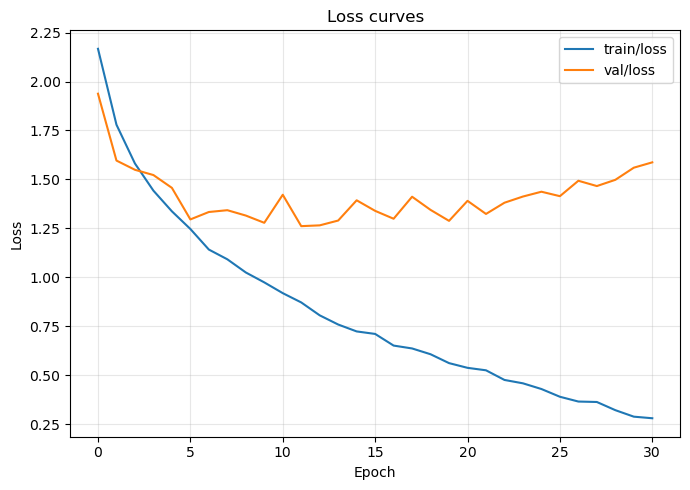

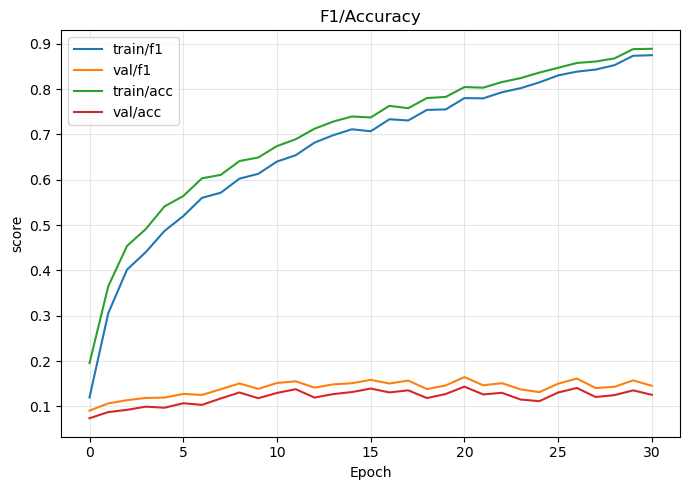

In [2]:
# ==== LOSS / MÉTRICAS POR ÉPOCA DESDE CSVLOGGER ====
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

LOG_ROOT = Path(r"C:\Users\RICHI\Documents\Tesis\TesisRichi\codigo\logs\vit")  # base del CSVLogger (igual que antes)

def get_latest_metrics_csv(log_root: Path):
    versions = sorted(log_root.glob("version_*"), key=lambda p: int(p.name.split("_")[-1]))
    assert versions, f"No hay versiones en {log_root}"
    last = versions[-1]
    csv_path = last / "metrics.csv"
    assert csv_path.exists(), f"No existe {csv_path}"
    return csv_path

csv_path = get_latest_metrics_csv(LOG_ROOT)
print("metrics.csv:", csv_path)
df = pd.read_csv(csv_path)

# Filtra filas con epoch definido
df = df.dropna(subset=["epoch"])

# Algunas columnas típicas: 'train/loss', 'val/loss', 'train/acc', 'val/acc', 'val/f1'
# Tomamos el último valor por epoch (Lightning a veces escribe varias filas)
agg = df.groupby("epoch").agg("last").reset_index()

# 1) Loss curves
plt.figure(figsize=(7,5))
if "train/loss" in agg.columns:
    plt.plot(agg["epoch"], agg["train/loss"], label="train/loss")
if "val/loss" in agg.columns:
    plt.plot(agg["epoch"], agg["val/loss"], label="val/loss")
plt.xlabel("Epoch"); plt.ylabel("Loss"); plt.title("Loss curves")
plt.legend(); plt.grid(True, alpha=0.3); plt.tight_layout()
Path("logs/analysis").mkdir(parents=True, exist_ok=True)
plt.savefig("logs/analysis/loss_curves.png", dpi=200)
plt.show()

# 2) (Opcional) F1/Accuracy
plt.figure(figsize=(7,5))
plotted = False
for col in ["train/f1","val/f1","train/acc","val/acc"]:
    if col in agg.columns:
        plt.plot(agg["epoch"], agg[col], label=col); plotted = True
if plotted:
    plt.xlabel("Epoch"); plt.ylabel("score"); plt.title("F1/Accuracy")
    plt.legend(); plt.grid(True, alpha=0.3); plt.tight_layout()
    plt.savefig("logs/analysis/metrics_curves.png", dpi=200)
    plt.show()
else:
    print("No encontré columnas de F1/Acc en metrics.csv; verifica nombres de métricas que estás logueando.")


In [ ]:
# ==== CONFUSION MATRIX + CLASIFICATION REPORT (TEST) ====
import torch, numpy as np, pandas as pd
from pathlib import Path
from sklearn.metrics import confusion_matrix, classification_report
import matplotlib.pyplot as plt

# === Ajusta si es necesario:
CKPT_PATH = Path("logs/vit")  # carpeta base del CSVLogger
DATA_ROOT = DATA_ROOT         # ya lo usabas
SPLITS    = SPLITS            # ya lo usabas (dict con 'train','val','test')

# 1) Resuelve el mejor checkpoint automáticamente (última versión)
def find_best_ckpt(log_root: Path):
    versions = sorted((log_root).glob("version_*"), key=lambda p: int(p.name.split("_")[-1]))
    assert versions, f"No hay versiones en {log_root}"
    last = versions[-1]
    ckpts = sorted((last/"checkpoints").glob("*.ckpt"))
    if ckpts:
        # prioriza el que incluye val_f1 o val_acc en nombre
        ckpts = sorted(ckpts, key=lambda p: ("val_f1" in p.name, "val_acc" in p.name, p.stat().st_mtime), reverse=True)
        return ckpts[0]
    return None

best_ckpt = find_best_ckpt(CKPT_PATH)
print("Best ckpt:", best_ckpt)

# 2) Re-arma DataModule y carga modelo
dm = MelLog2DDataModule(DATA_ROOT, SPLITS, batch_size=BATCH_SIZE, num_workers=NUM_WORKERS, size=IMG_SIZE)
dm.setup()
class_names = sorted([d.name for d in (DATA_ROOT/SPLITS['train']).iterdir() if d.is_dir()])

device = "cuda" if torch.cuda.is_available() else "cpu"
if best_ckpt is not None:
    model = ViTClassifierPL.load_from_checkpoint(str(best_ckpt))
else:
    # fallback: usa pesos actuales (si tienes 'model' ya instanciado)
    model = model
model.eval().to(device)

# 3) Predicción test
y_true, y_pred = [], []
with torch.no_grad():
    for xb, yb in dm.test_dataloader():
        xb = xb.to(device, non_blocking=True)
        yb = yb.to(device, non_blocking=True)
        logits = model(xb)
        preds = logits.argmax(1)
        y_true.append(yb.cpu().numpy())
        y_pred.append(preds.cpu().numpy())
y_true = np.concatenate(y_true)
y_pred = np.concatenate(y_pred)

# 4) Matriz de confusión (absoluta y normalizada por filas)
cm_abs = confusion_matrix(y_true, y_pred, labels=list(range(len(class_names))))
cm_norm = cm_abs.astype(float) / cm_abs.sum(axis=1, keepdims=True).clip(min=1)

out_dir = Path("logs/analysis"); out_dir.mkdir(parents=True, exist_ok=True)
pd.DataFrame(cm_abs, index=class_names, columns=class_names).to_csv(out_dir/"confusion_matrix_test_abs.csv", encoding="utf-8")
pd.DataFrame(cm_norm, index=class_names, columns=class_names).to_csv(out_dir/"confusion_matrix_test_norm.csv", encoding="utf-8")

# 5) Plot bonito (normalizada)
plt.figure(figsize=(9,7))
plt.imshow(cm_norm, interpolation="nearest")
plt.title("Confusion Matrix (test) - normalized")
plt.colorbar()
tick = np.arange(len(class_names))
plt.xticks(tick, class_names, rotation=90)
plt.yticks(tick, class_names)
plt.xlabel("Predicted")
plt.ylabel("True")
plt.tight_layout()
plt.savefig(out_dir/"confusion_matrix_test.png", dpi=200)
plt.show()

# 6) Reporte por clase (precision/recall/F1)
rep = classification_report(y_true, y_pred, target_names=class_names, digits=4, output_dict=True)
pd.DataFrame(rep).to_csv(out_dir/"classification_report_test.csv", encoding="utf-8")
print("Guardado en:", out_dir)
